# 07. Resíduo de ruído na busca cega de copy-move

A busca cega de copy-move (notebook 03) compara caracteres pela intensidade e gera muitos falsos alarmes em recibos autênticos: caracteres iguais impressos mais de uma vez (dígitos, letras) têm formas quase idênticas. A hipótese deste notebook é que o **ruído de digitalização** distingue os dois casos: um caractere impresso duas vezes passa duas vezes pelo scanner e recebe ruído diferente em cada ocorrência, enquanto uma cópia digital carrega o mesmo ruído nos dois lugares.

O ruído é medido pelo **resíduo**: a imagem em tons de cinza menos a sua mediana k x k (filtro da mediana, slides 201-216 do material da disciplina), na resolução original. Cada par candidato da busca cega atual é mantido apenas se a correlação normalizada (slides 260-272) entre os resíduos das duas caixas atingir um limiar, testando deslocamentos de até 2 px para compensar o arredondamento do mapeamento da escala de 1000 px para a resolução original.

O experimento usa apenas os splits `train` (diagnóstico) e `val` (escolha de parâmetros) do *Find it again!*, além do conjunto sintético de desenvolvimento do CORD. O split `test` não é aberto em nenhuma etapa. Seed 42. Os números aparecem apenas como saída das células; este notebook não registra conclusões.

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul")
warnings.filterwarnings("ignore", category=RuntimeWarning)

import hashlib
import itertools
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from copy_move import filter_pairs
from avaliacao_sintetica import carregar_amostras
from copy_move_residuo import (KS, avaliar_config, candidatos_lote, cobertura, correlacoes_regioes_cpi, escolher,
                               filtrar_pares, separacao_auc)
from dataset_loader import load_dataset

RAIZ = Path("..")
DATASET_ROOT = str(RAIZ / "data/findit2")

## 1. Grade e critérios congelados

A grade, os critérios de escolha e de sucesso e o SHA-256 do código (`src/copy_move_residuo.py`) foram gravados em `results/grade_residuo.json` antes de qualquer execução sobre imagens reais. A célula confere que o código atual ainda tem o hash registrado e mostra a grade.

In [2]:
grade = json.loads((RAIZ / "results/grade_residuo.json").read_text(encoding="utf-8"))
hash_atual = hashlib.sha256((RAIZ / grade["arquivo"]).read_bytes()).hexdigest()
print("congelado em:", grade["congelado_em"])
print("código idêntico ao congelado:", hash_atual == grade["sha256"])
print(json.dumps({k: grade[k] for k in ("grade", "criterio_escolha", "criterio_sucesso")}, ensure_ascii=False, indent=1))

congelado em: 2026-11-06T10:50:57
código idêntico ao congelado: True
{
 "grade": {
  "piso_intensidade": [
   0.95,
   0.97,
   0.99
  ],
  "mediana_k": [
   3,
   5
  ],
  "limiar_residuo": [
   0.3,
   0.4,
   0.5,
   0.6,
   0.7,
   0.8,
   0.9
  ],
  "min_side_fixo": 6,
  "cobertura_minima_fixa": 0.5,
  "deslocamento_px": 2,
  "n_configuracoes": 42
 },
 "criterio_escolha": {
  "conjunto": "val do Find it again!",
  "medida": "J = taxa de imagens com CPI com algum par - taxa de imagens autênticas com algum par",
  "desempate": "maior cobertura de regiões CPI"
 },
 "criterio_sucesso": {
  "J_val_min": 0.295,
  "cobertura_val_min": 0.079,
  "se_nao_atingir": "registrar como resultado negativo"
 }
}


## 2. Diagnóstico no train: o resíduo separa cópia de repetição?

Antes de escolher qualquer parâmetro, mede-se a correlação do resíduo em dois grupos de imagens do split `train`:

- **(a) Regiões CPI anotadas** (copiar e colar dentro do documento): a correlação do resíduo entre a região e o ponto do pico de correlação de intensidade, como no notebook 03. O grupo inclui regiões cujo pico de intensidade é baixo (não são cópias exatas, por exemplo regiões editadas depois da colagem); por isso reporta-se também o subgrupo com pico de intensidade de pelo menos 0,979 (limiar do notebook 03), que são as cópias quase exatas.
- **(b) Pares encontrados pela busca cega atual** (limiar de intensidade 0,99) em imagens **autênticas**: repetições de caracteres impressos.

Se as distribuições se sobrepuserem quase por completo, a técnica não tem como funcionar e o experimento deve parar aqui. Reportam-se, para k = 3 e k = 5, as medianas, os quartis e a AUC da separação do grupo (a) contra o (b).

In [3]:
train = [s for s in load_dataset(DATASET_ROOT, "train") if s.image_path.exists()]
cpi_train = [s for s in train if s.is_tampered and s.regions and "CPI" in s.tamper_types]
aut_train = [s for s in train if not s.is_tampered]
regioes_cpi = {str(s.image_path): [r.bbox for r in s.regions
                                   if r.is_original_area is not True and r.modification and "CPI" in r.modification]
               for s in cpi_train}
regioes_cpi = {n: caixas for n, caixas in regioes_cpi.items() if caixas}
print("train | imagens com CPI:", len(regioes_cpi), "| regiões CPI:", sum(map(len, regioes_cpi.values())),
      "| imagens autênticas:", len(aut_train))

aviso: 1 imagens com anotação ausente/malformada tratadas como regions=[] (train)
aviso: 2 imagens com forged divergente da anotação (train): ['X51008114260.png', 'X51006619709.png']
aviso: 2 regiões marcadas como área original mas com modificação real (train)
train | imagens com CPI: 74 | regiões CPI: 203 | imagens autênticas: 483


In [4]:
grupo_a = pd.DataFrame(correlacoes_regioes_cpi(regioes_cpi))
print("regiões CPI com pico definido:", len(grupo_a))
print(grupo_a[["pico", "residuo_k3", "residuo_k5"]].describe().round(3).to_string())

regiões CPI com pico definido: 203
          pico  residuo_k3  residuo_k5
count  203.000     203.000     203.000
mean     0.918       0.789       0.838
std      0.189       0.322       0.272
min     -1.000       0.000      -0.000
25%      0.911       0.650       0.804
50%      0.998       0.971       0.982
75%      1.000       0.998       0.998
max      1.000       1.000       1.000


In [5]:
cands_aut_train = candidatos_lote([s.image_path for s in aut_train])
# pares que a busca atual mantém (piso 0,99, com a remoção de redundância); o resíduo vem dos candidatos
linhas_b = []
for nome, cands in cands_aut_train.items():
    mantidos = {(par[0], par[1]) for par in filtrar_pares(cands, 0.99)}
    linhas_b += [{"imagem": nome, "intensidade": r, **{f"residuo_k{k}": res[k] for k in KS}}
                 for src, dst, r, res in cands if (src, dst) in mantidos]
grupo_b = pd.DataFrame(linhas_b)
print("imagens autênticas com algum par (piso 0,99):", grupo_b["imagem"].nunique(), "de", len(aut_train))
print("pares em autênticas:", len(grupo_b))
print(grupo_b[["intensidade", "residuo_k3", "residuo_k5"]].describe().round(3).to_string())

imagens autênticas com algum par (piso 0,99): 72 de 483
pares em autênticas: 154
       intensidade  residuo_k3  residuo_k5
count      154.000     154.000     154.000
mean         0.993       0.749       0.873
std          0.003       0.226       0.175
min          0.990       0.059       0.117
25%          0.991       0.627       0.862
50%          0.992       0.787       0.917
75%          0.993       0.936       0.974
max          1.000       1.000       1.000


Medianas, quartis e AUC da separação. Os valores indefinidos (trecho liso, correlação sem definição) ficam de fora de cada estatística e são contados.

In [6]:
resumo = []
subgrupos = {"(a) todas as regiões CPI": grupo_a, "(a') regiões CPI com pico >= 0,979": grupo_a[grupo_a["pico"] >= 0.979]}
for k in KS:
    b = grupo_b[f"residuo_k{k}"].dropna()
    for nome, a_df in subgrupos.items():
        a = a_df[f"residuo_k{k}"].dropna()
        resumo.append({"k": k, "grupo": nome, "n_a": len(a), "n_indefinidos_a": int(a_df[f"residuo_k{k}"].isna().sum()),
                       "mediana_a": a.median(), "q1_a": a.quantile(.25), "q3_a": a.quantile(.75),
                       "n_b": len(b), "n_indefinidos_b": int(grupo_b[f"residuo_k{k}"].isna().sum()),
                       "mediana_b": b.median(), "q1_b": b.quantile(.25), "q3_b": b.quantile(.75),
                       "auc": separacao_auc(a, b)})
resumo = pd.DataFrame(resumo)
pd.set_option("display.width", 250)
print(resumo.round(3).to_string(index=False))

 k                              grupo  n_a  n_indefinidos_a  mediana_a  q1_a  q3_a  n_b  n_indefinidos_b  mediana_b  q1_b  q3_b   auc
 3           (a) todas as regiões CPI  203                0      0.971 0.650 0.998  154                0      0.787 0.627 0.936 0.646
 3 (a') regiões CPI com pico >= 0,979  133                0      0.994 0.971 0.999  154                0      0.787 0.627 0.936 0.876
 5           (a) todas as regiões CPI  203                0      0.982 0.804 0.998  154                0      0.917 0.862 0.974 0.607
 5 (a') regiões CPI com pico >= 0,979  133                0      0.996 0.982 0.999  154                0      0.917 0.862 0.974 0.843


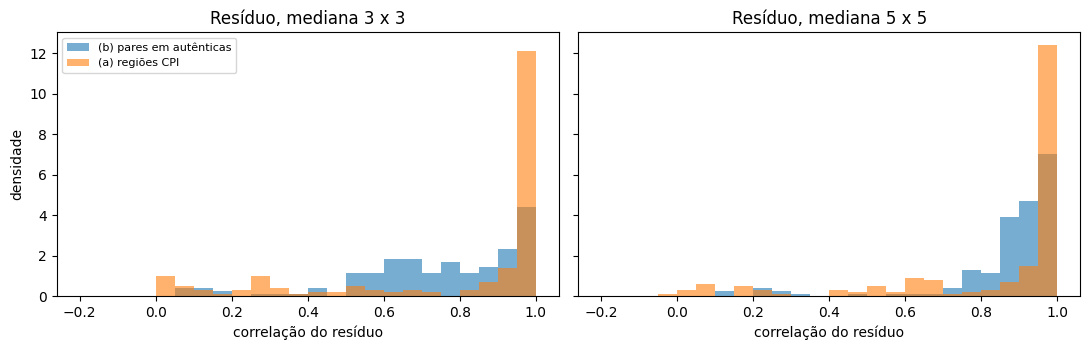

In [7]:
fig, eixos = plt.subplots(1, len(KS), figsize=(11, 3.6), sharey=True)
for eixo, k in zip(eixos, KS):
    bins = np.linspace(-0.2, 1.0, 25)
    eixo.hist(grupo_b[f"residuo_k{k}"].dropna(), bins=bins, alpha=.6, density=True, label="(b) pares em autênticas")
    eixo.hist(grupo_a[f"residuo_k{k}"].dropna(), bins=bins, alpha=.6, density=True, label="(a) regiões CPI")
    eixo.set_title(f"Resíduo, mediana {k} x {k}")
    eixo.set_xlabel("correlação do resíduo")
eixos[0].set_ylabel("densidade")
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Escolha no val

No split `val` calcula-se, para cada uma das 42 configurações da grade (piso de intensidade x mediana k x limiar do resíduo, com `MIN_SIDE` 6 e cobertura mínima 0,5 fixos), a taxa de imagens com CPI com algum par, a taxa de imagens autênticas com algum par, J (a diferença entre as duas), a cobertura das regiões CPI (região coberta quando uma caixa de par cobre pelo menos metade dela, como no notebook 03) e o número de pares por imagem autêntica. A linha "só intensidade" é a busca cega atual, recalculada aqui pelo mesmo caminho de código, e serve de referência. A escolha segue o critério congelado: maior J, desempate pela maior cobertura.

In [8]:
val = [s for s in load_dataset(DATASET_ROOT, "val") if s.image_path.exists()]
cpi_val = [s for s in val if s.is_tampered and s.regions and "CPI" in s.tamper_types]
aut_val = [s for s in val if not s.is_tampered]
regioes_val = {str(s.image_path): [r.bbox for r in s.regions
                                   if r.is_original_area is not True and r.modification and "CPI" in r.modification]
               for s in cpi_val}
regioes_val = {n: caixas for n, caixas in regioes_val.items() if caixas}
cands_val = candidatos_lote([s.image_path for s in cpi_val + aut_val])
cands_cpi = {n: cands_val[n] for n in regioes_val}
cands_aut = {str(s.image_path): cands_val[str(s.image_path)] for s in aut_val}
print("val | imagens com CPI:", len(cands_cpi), "| regiões CPI:", sum(map(len, regioes_val.values())), "| autênticas:", len(cands_aut))
print("pares candidatos (piso 0,95):", sum(len(c) for c in cands_val.values()))

aviso: 1 imagens listadas em val.txt e ausentes de val/ foram ignoradas: ['X51006619709.png']
aviso: 1 regiões marcadas como área original mas com modificação real (val)


val | imagens com CPI: 26 | regiões CPI: 76 | autênticas: 159
pares candidatos (piso 0,95): 15774


In [9]:
referencia = [avaliar_config(cands_cpi, regioes_val, cands_aut, piso) for piso in grade["grade"]["piso_intensidade"]]
linhas = [avaliar_config(cands_cpi, regioes_val, cands_aut, piso, k, limiar)
          for piso, k, limiar in itertools.product(grade["grade"]["piso_intensidade"], grade["grade"]["mediana_k"],
                                                   grade["grade"]["limiar_residuo"])]
colunas = ["piso", "k", "limiar_residuo", "taxa_cpi", "taxa_autenticas", "J", "cobertura", "pares_por_autentica", "pares_por_autentica_com_par"]
pd.set_option("display.width", 250)
print("só intensidade (busca atual):")
print(pd.DataFrame(referencia)[colunas].round(3).to_string(index=False))
print("\ngrade (42 configurações):")
print(pd.DataFrame(linhas)[colunas].round(3).to_string(index=False))

só intensidade (busca atual):
 piso    k limiar_residuo  taxa_cpi  taxa_autenticas     J  cobertura  pares_por_autentica  pares_por_autentica_com_par
 0.95 None           None     0.962            0.906 0.056      0.171               85.635                       94.556
 0.97 None           None     0.846            0.742 0.104      0.132               23.453                       31.602
 0.99 None           None     0.346            0.151 0.195      0.079                0.314                        2.083

grade (42 configurações):
 piso  k  limiar_residuo  taxa_cpi  taxa_autenticas     J  cobertura  pares_por_autentica  pares_por_autentica_com_par
 0.95  3             0.3     0.923            0.811 0.112      0.171               80.151                       98.791
 0.95  3             0.4     0.923            0.799 0.124      0.171               73.283                       91.748
 0.95  3             0.5     0.885            0.792 0.092      0.158               58.214                 

Escolha pelo critério congelado e verificação do critério de sucesso (J no val de pelo menos 0,295 e cobertura de regiões CPI de pelo menos 7,9%).

In [10]:
escolhida = escolher(linhas)
padrao_atual = next(l for l in referencia if l["piso"] == 0.99)
sucesso = escolhida["J"] >= grade["criterio_sucesso"]["J_val_min"] and escolhida["cobertura"] >= grade["criterio_sucesso"]["cobertura_val_min"]
print("escolhida:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in escolhida.items()})
print("busca atual (piso 0,99):", {k: round(padrao_atual[k], 3) for k in ("J", "taxa_cpi", "taxa_autenticas", "cobertura")})
print("critério de sucesso atingido:", sucesso)

escolhida: {'piso': 0.95, 'k': 3, 'limiar_residuo': 0.9, 'taxa_cpi': 0.538, 'taxa_autenticas': 0.22, 'J': 0.318, 'cobertura': 0.132, 'regioes_cobertas': 10, 'regioes_total': 76, 'pares_por_autentica': 1.113, 'pares_por_autentica_com_par': 5.057}
busca atual (piso 0,99): {'J': 0.195, 'taxa_cpi': 0.346, 'taxa_autenticas': 0.151, 'cobertura': 0.079}
critério de sucesso atingido: True


## 4. Verificação no CORD sintético de desenvolvimento (só cobertura)

No conjunto `data/cord_sintetico_dev/` (766 notas do treino do CORD com uma colagem exata de caixa de texto cada, gerador congelado), mede-se a fração de colagens cuja caixa é coberta (pelo menos 50%) por uma caixa de par, com a configuração escolhida, com a busca atual (piso 0,99, sem resíduo) e, como referência, com o piso da escolhida sem o filtro do resíduo. As colagens são cópias exatas, então a medida só mostra se a implementação encontra cópias; não mede falso alarme, porque o conjunto não tem notas autênticas.

In [11]:
dev = carregar_amostras(RAIZ / "data/cord_sintetico_dev")
regioes_dev = {str(s.image_path): [r.bbox for r in s.regions] for s in dev}
cands_dev = candidatos_lote([s.image_path for s in dev])
cord = {"escolhida": cobertura(cands_dev, regioes_dev, escolhida["piso"], escolhida["k"], escolhida["limiar_residuo"]),
        "busca_atual_0.99": cobertura(cands_dev, regioes_dev, 0.99),
        "piso_da_escolhida_sem_residuo": cobertura(cands_dev, regioes_dev, escolhida["piso"])}
for nome, (cobertas, total) in cord.items():
    print(f"{nome:32} {cobertas}/{total} = {cobertas / total:.1%}")

escolhida                        30/766 = 3.9%
busca_atual_0.99                 14/766 = 1.8%
piso_da_escolhida_sem_residuo    40/766 = 5.2%


## 5. Registro dos resultados

Os números das células anteriores vão para `results/copy_move_residuo_val.json`, sem texto interpretativo.

In [12]:
saida = {"grade_sha256": hash_atual, "diagnostico_train": {"regioes_cpi": len(grupo_a), "pares_autenticas": len(grupo_b),
                                                         "resumo": resumo.replace({np.nan: None}).to_dict("records")},
         "val": {"imagens_cpi": len(cands_cpi), "regioes_cpi": sum(map(len, regioes_val.values())), "autenticas": len(cands_aut),
                 "so_intensidade": referencia, "grade": linhas, "escolhida": escolhida, "criterio_sucesso_atingido": bool(sucesso)},
         "cord_dev": {nome: {"cobertas": c, "total": t, "taxa": c / t} for nome, (c, t) in cord.items()}}
(RAIZ / "results/copy_move_residuo_val.json").write_text(json.dumps(saida, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("gravado")

gravado
